In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

print("All libraries imported successfully!")

All libraries imported successfully!


In [68]:
data = {
    "Review": [
        "This product is excellent and amazing",
        "I love this product",
        "Very good quality and fast delivery",
        "The product is fantastic",
        "I am very happy with this purchase",
        "Worst product ever",
        "Very bad quality",
        "I hate this product",
        "Delivery was late and disappointing",
        "The product is terrible",
        "The product is okay",
        "It is an average product",
        "Nothing special about it",
        "The product is acceptable",
        "It is neither good nor bad"
    ]
}

df = pd.DataFrame(data)

display(df)

,Review
0,This product is excellent and amazing
1,I love this product
2,Very good quality and fast delivery
3,The product is fantastic
4,I am very happy with this purchase
5,Worst product ever
6,Very bad quality
7,I hate this product
8,Delivery was late and disappointing
9,The product is terrible


In [69]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display first five reviews
print("\nFirst 5 Reviews:")
display(df.head())

Dataset Shape: (15, 1)

Column Names:
Index(['Review'], dtype='object')

Missing Values:
Review    0
dtype: int64

First 5 Reviews:


,Review
0,This product is excellent and amazing
1,I love this product
2,Very good quality and fast delivery
3,The product is fantastic
4,I am very happy with this purchase


In [70]:
# Function to clean text
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Apply text cleaning
df["Cleaned_Review"] = df["Review"].apply(clean_text)

# Display original and cleaned reviews
display(df[["Review", "Cleaned_Review"]])

,Review,Cleaned_Review
0,This product is excellent and amazing,this product is excellent and amazing
1,I love this product,i love this product
2,Very good quality and fast delivery,very good quality and fast delivery
3,The product is fantastic,the product is fantastic
4,I am very happy with this purchase,i am very happy with this purchase
5,Worst product ever,worst product ever
6,Very bad quality,very bad quality
7,I hate this product,i hate this product
8,Delivery was late and disappointing,delivery was late and disappointing
9,The product is terrible,the product is terrible


In [71]:
# Define sentiment classification
def get_sentiment(text):
    positive_words = ["excellent", "amazing", "love", "good",
                      "fantastic", "happy", "great"]
    negative_words = ["worst", "bad", "hate", "late",
                      "disappointing", "terrible"]

    words = text.split()

    positive_count = sum(word in positive_words for word in words)
    negative_count = sum(word in negative_words for word in words)

    if positive_count > negative_count:
        return "Positive"
    elif negative_count > positive_count:
        return "Negative"
    else:
        return "Neutral"

# Apply sentiment classification
df["Sentiment"] = df["Cleaned_Review"].apply(get_sentiment)

display(df[["Cleaned_Review", "Sentiment"]])

,Cleaned_Review,Sentiment
0,this product is excellent and amazing,Positive
1,i love this product,Positive
2,very good quality and fast delivery,Positive
3,the product is fantastic,Positive
4,i am very happy with this purchase,Positive
5,worst product ever,Negative
6,very bad quality,Negative
7,i hate this product,Negative
8,delivery was late and disappointing,Negative
9,the product is terrible,Negative


In [72]:
# Count each sentiment category
sentiment_counts = df["Sentiment"].value_counts()

print("Sentiment Analysis Results:")
print(sentiment_counts)

Sentiment Analysis Results:
Sentiment
Positive    5
Negative    5
Neutral     5
Name: count, dtype: int64


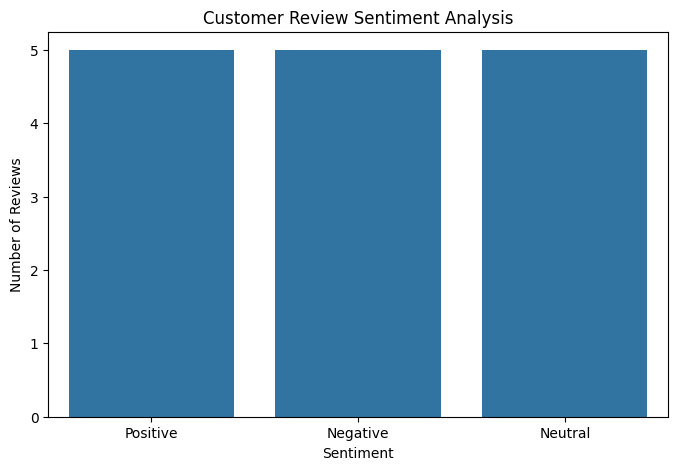

In [73]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Sentiment")

plt.title("Customer Review Sentiment Analysis")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [74]:
# Calculate sentiment percentages
sentiment_percentages = df["Sentiment"].value_counts(normalize=True) * 100

print("Sentiment Percentages:")
print(sentiment_percentages.round(2))

Sentiment Percentages:
Sentiment
Positive    33.33
Negative    33.33
Neutral     33.33
Name: proportion, dtype: float64


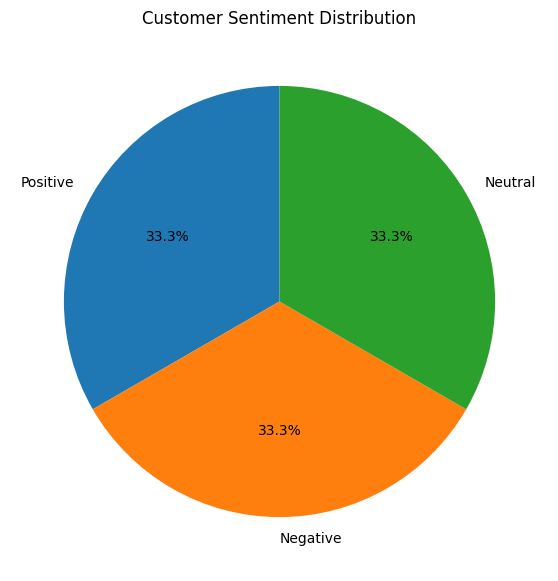

In [75]:
plt.figure(figsize=(7, 7))

sentiment_counts = df["Sentiment"].value_counts()

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Sentiment Distribution")
plt.show()

In [76]:
# Display final sentiment analysis
display(df[["Review", "Cleaned_Review", "Sentiment"]])

# Print overall summary
print("\nTotal Reviews:", len(df))
print("Positive Reviews:", (df["Sentiment"] == "Positive").sum())
print("Negative Reviews:", (df["Sentiment"] == "Negative").sum())
print("Neutral Reviews:", (df["Sentiment"] == "Neutral").sum())

,Review,Cleaned_Review,Sentiment
0,This product is excellent and amazing,this product is excellent and amazing,Positive
1,I love this product,i love this product,Positive
2,Very good quality and fast delivery,very good quality and fast delivery,Positive
3,The product is fantastic,the product is fantastic,Positive
4,I am very happy with this purchase,i am very happy with this purchase,Positive
5,Worst product ever,worst product ever,Negative
6,Very bad quality,very bad quality,Negative
7,I hate this product,i hate this product,Negative
8,Delivery was late and disappointing,delivery was late and disappointing,Negative
9,The product is terrible,the product is terrible,Negative



Total Reviews: 15
Positive Reviews: 5
Negative Reviews: 5
Neutral Reviews: 5


In [77]:
# Save sentiment analysis results
df.to_csv("Sentiment_Analysis_Results.csv", index=False)

print("Sentiment analysis results saved successfully!")

Sentiment analysis results saved successfully!


In [78]:
from google.colab import files
files.download("Sentiment_Analysis_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Task 4: Sentiment Analysis

## Objective
To analyse customer reviews and classify them into Positive, Negative, and Neutral sentiments using Python.

## Dataset
A sample dataset containing 15 customer reviews.

## Tools Used
- Python
- Pandas
- Matplotlib
- Seaborn
- Regular Expressions (re)

## Methodology
1. Created a customer review dataset.
2. Checked the dataset for missing values.
3. Cleaned the text by converting it to lowercase and removing special characters.
4. Classified reviews using a rule-based sentiment analysis method.
5. Calculated sentiment counts and percentages.
6. Visualised the results using bar charts and pie charts.
7. Exported the results to a CSV file.

## Observations
- Positive reviews contain words such as excellent, love, and fantastic.
- Negative reviews contain words such as worst, bad, and terrible.
- Neutral reviews contain no matching sentiment words or have equal positive and negative word counts.

## Conclusion
This project demonstrates basic rule-based sentiment analysis using Python. It helps identify customer opinions from text reviews. However, the method has limitations when handling sarcasm, context, and complex sentences.